In [1]:
import numpy as np
import matplotlib.pyplot as plt

Si consideri una catena di Markov con sei stati, per cui E = {1, 2, 3, 4, 5, 6}. Se mi trovo in i = 1 ho
il 50% di probabilità di restare in 1 o di andare in 2. Se mi trovo in i = 6 ho il 50% di probabilità di
restare in 6 o di andare in 5.Se mi trovo nello stato i 6 = 1, 6 ho il 50% di probabilità di andare nello
stato i + 1 e il 50% di andare nello stato i − 1. Scrivere la matrice di transizione associata a questa
catena e rappresentarla su un grafo.

In [3]:
#Creo la matrice di transizione
P1 = [0.5, 0.5, 0, 0, 0, 0]
P2 = [0.5, 0, 0.5, 0, 0, 0]
P3 = [0, 0.5, 0, 0.5, 0, 0]
P4 = [0, 0, 0.5, 0, 0.5, 0]
P5 = [0, 0, 0, 0.5, 0, 0.5]
P6 = [0, 0, 0, 0, 0.5, 0.5]
P = np.matrix([P1, P2, P3, P4, P5, P6])
print(P)
print(P*P*P*P*P)

[[0.5 0.5 0.  0.  0.  0. ]
 [0.5 0.  0.5 0.  0.  0. ]
 [0.  0.5 0.  0.5 0.  0. ]
 [0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5]
 [0.  0.  0.  0.  0.5 0.5]]
[[0.3125  0.3125  0.15625 0.15625 0.03125 0.03125]
 [0.3125  0.15625 0.3125  0.03125 0.15625 0.03125]
 [0.15625 0.3125  0.03125 0.3125  0.03125 0.15625]
 [0.15625 0.03125 0.3125  0.03125 0.3125  0.15625]
 [0.03125 0.15625 0.03125 0.3125  0.15625 0.3125 ]
 [0.03125 0.03125 0.15625 0.15625 0.3125  0.3125 ]]


In [6]:
#Diagonalizzo la matrice
eps, w = np.linalg.eig(P)
print(eps)
print(w)
i = np.where(np.isclose(eps, 1, atol=1e-10))[0]
print(eps[i])
print(w[:,i]/sum(w[:,i]))

[-8.66025404e-01 -5.00000000e-01  6.71584422e-17  5.00000000e-01
  1.00000000e+00  8.66025404e-01]
[[ 1.49429245e-01  2.88675135e-01 -4.08248290e-01  5.00000000e-01
  -4.08248290e-01 -5.57677536e-01]
 [-4.08248290e-01 -5.77350269e-01  4.08248290e-01  2.58372537e-16
  -4.08248290e-01 -4.08248290e-01]
 [ 5.57677536e-01  2.88675135e-01  4.08248290e-01 -5.00000000e-01
  -4.08248290e-01 -1.49429245e-01]
 [-5.57677536e-01  2.88675135e-01 -4.08248290e-01 -5.00000000e-01
  -4.08248290e-01  1.49429245e-01]
 [ 4.08248290e-01 -5.77350269e-01 -4.08248290e-01  3.34606690e-16
  -4.08248290e-01  4.08248290e-01]
 [-1.49429245e-01  2.88675135e-01  4.08248290e-01  5.00000000e-01
  -4.08248290e-01  5.57677536e-01]]
[1.]
[[0.16666667]
 [0.16666667]
 [0.16666667]
 [0.16666667]
 [0.16666667]
 [0.16666667]]


In [7]:
#Verifico che sia realmente la distribuzione stazionaria
v = np.array([1./6, 1./6, 1./6, 1./6, 1./6, 1./6])
N = 10
for i in range(N):
    v = v*P
    print(v)

[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]
[[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]]


In [10]:
#Provo altre distribuzioni
v = np.array([1, 0, 0, 0, 0, 0])
N = 100
for i in range(N):
    v0 = v
    v = v*P
    print(v)

[[0.5 0.5 0.  0.  0.  0. ]]
[[0.5  0.25 0.25 0.   0.   0.  ]]
[[0.375 0.375 0.125 0.125 0.    0.   ]]
[[0.375  0.25   0.25   0.0625 0.0625 0.    ]]
[[0.3125  0.3125  0.15625 0.15625 0.03125 0.03125]]
[[0.3125   0.234375 0.234375 0.09375  0.09375  0.03125 ]]
[[0.2734375 0.2734375 0.1640625 0.1640625 0.0625    0.0625   ]]
[[0.2734375  0.21875    0.21875    0.11328125 0.11328125 0.0625    ]]
[[0.24609375 0.24609375 0.16601562 0.16601562 0.08789062 0.08789062]]
[[0.24609375 0.20605469 0.20605469 0.12695312 0.12695312 0.08789062]]
[[0.22607422 0.22607422 0.16650391 0.16650391 0.10742188 0.10742188]]
[[0.22607422 0.19628906 0.19628906 0.13696289 0.13696289 0.10742188]]
[[0.21118164 0.21118164 0.16662598 0.16662598 0.12219238 0.12219238]]
[[0.21118164 0.18890381 0.18890381 0.14440918 0.14440918 0.12219238]]
[[0.20004272 0.20004272 0.16665649 0.16665649 0.13330078 0.13330078]]
[[0.20004272 0.18334961 0.18334961 0.14997864 0.14997864 0.13330078]]
[[0.19169617 0.19169617 0.16666412 0.16666412 0.

In [12]:
v = np.array([0, 0, 0, 0.5, 0, 0.5])
N = 10
for i in range(N):
    v0 = v
    v = v*P
    print(v)

[[0.   0.   0.25 0.   0.5  0.25]]
[[0.    0.125 0.    0.375 0.125 0.375]]
[[0.0625 0.     0.25   0.0625 0.375  0.25  ]]
[[0.03125 0.15625 0.03125 0.3125  0.15625 0.3125 ]]
[[0.09375  0.03125  0.234375 0.09375  0.3125   0.234375]]
[[0.0625    0.1640625 0.0625    0.2734375 0.1640625 0.2734375]]
[[0.11328125 0.0625     0.21875    0.11328125 0.2734375  0.21875   ]]
[[0.08789062 0.16601562 0.08789062 0.24609375 0.16601562 0.24609375]]
[[0.12695312 0.08789062 0.20605469 0.12695312 0.24609375 0.20605469]]
[[0.10742188 0.16650391 0.10742188 0.22607422 0.16650391 0.22607422]]


In [13]:
v = np.array([1./3, 0, 1./3, 0, 1./3, 0])
N = 10
for i in range(N):
    v0 = v
    v = v*P
    print(v)

[[0.16666667 0.33333333 0.         0.33333333 0.         0.16666667]]
[[0.25       0.08333333 0.33333333 0.         0.25       0.08333333]]
[[0.16666667 0.29166667 0.04166667 0.29166667 0.04166667 0.16666667]]
[[0.22916667 0.10416667 0.29166667 0.04166667 0.22916667 0.10416667]]
[[0.16666667 0.26041667 0.07291667 0.26041667 0.07291667 0.16666667]]
[[0.21354167 0.11979167 0.26041667 0.07291667 0.21354167 0.11979167]]
[[0.16666667 0.23697917 0.09635417 0.23697917 0.09635417 0.16666667]]
[[0.20182292 0.13151042 0.23697917 0.09635417 0.20182292 0.13151042]]
[[0.16666667 0.21940104 0.11393229 0.21940104 0.11393229 0.16666667]]
[[0.19303385 0.14029948 0.21940104 0.11393229 0.19303385 0.14029948]]


In [14]:
#Proviamo a simulare la catena di Markov. Immaginiamo di partire dallo stato i.
i = 3
v = np.zeros(6)
v[i] = 1
print(v)

[0. 0. 0. 1. 0. 0.]


Per generare il successivo stato, dobbiamo pescare un numero random casuale tra quelli possibili. Questa è una distribuzione multinomiale, in cui le probabilità sono quelle date dalla riga i-esima della matrice di transizione.

In [19]:
F = np.array(np.cumsum(P[i])).ravel()
print(F)
test = np.random.rand()
print(test)
stato = np.searchsorted(F, test)  
#stato = np.where(test >= F)[0]
print(stato)

[0.  0.  0.5 0.5 1.  1. ]
0.6627491697965819
4


In [26]:
N =5000
stato = np.zeros(N)
for j in range(N):
    F = np.array(np.cumsum(P[i])).ravel()
    test = np.random.rand()
    i = np.searchsorted(F, test)
    stato[j] = i
    #print(i)
print(stato)

[3. 2. 3. ... 2. 1. 0.]


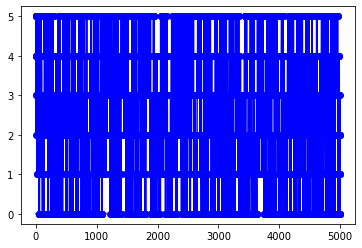

In [27]:
x = np.arange(N)
y = np.matrix([0, 1, 2, 3, 4, 5])
y = np.repeat(y, N, axis = 0)
#print(y)
plt.plot(x, y, 'r-')
plt.plot(x, stato, 'bo-')
plt.show()

In [28]:
w_mc = np.unique(stato, return_counts = 'True')
print(w_mc[1]/N)

[0.1646 0.1594 0.1678 0.1796 0.171  0.1576]


In [29]:
#Creo la matrice di transizione
P1 = [0, 0.25, 0.75]
P2 = [0, 0.5, 0.5]
P3 = [0.75, 0, 0.25]
P = np.matrix([P1, P2, P3])
print(P)

[[0.   0.25 0.75]
 [0.   0.5  0.5 ]
 [0.75 0.   0.25]]


In [30]:
#Diagonalizzo la matrice
Pt = np.matrix.transpose(P)
print(Pt)
eps, w = np.linalg.eig(Pt)
#print(eps)
#print(w)
i = np.where(np.isclose(eps, 1, atol=1e-10))[0]
print(i)
print(w[:,i]/sum(w[:,i]))

[[0.   0.   0.75]
 [0.25 0.5  0.  ]
 [0.75 0.5  0.25]]
[1]
[[0.35294118]
 [0.17647059]
 [0.47058824]]


In [31]:
#Proviamo a simulare la catena di Markov. Immaginiamo di partire dallo stato i.
i = 1
v = np.zeros(3)
v[i] = 1
print(v)

[0. 1. 0.]


In [32]:
F = np.array(np.cumsum(P[i])).ravel()
print(F)
test = np.random.rand()
print(test)
stato = np.searchsorted(F, test)  
#stato = np.where(test >= F)[0]
print(stato)

[0.  0.5 1. ]
0.16083679970659948
1


In [33]:
N = 1000
stato = np.zeros(N)
for j in range(N):
    F = np.array(np.cumsum(P[i])).ravel()
    test = np.random.rand()
    i = np.searchsorted(F, test)
    stato[j] = i
    #print(i)
print(stato)

[1. 1. 1. 2. 0. 2. 0. 2. 0. 2. 0. 2. 2. 0. 2. 0. 1. 1. 1. 2. 2. 0. 1. 1.
 1. 1. 2. 0. 2. 2. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2. 2. 2. 2. 0. 2. 2. 0.
 2. 0. 2. 0. 2. 0. 1. 2. 0. 1. 1. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 1.
 2. 0. 2. 2. 0. 2. 0. 1. 2. 0. 2. 0. 2. 0. 2. 2. 0. 1. 1. 1. 2. 2. 2. 0.
 1. 2. 2. 0. 1. 2. 0. 2. 0. 2. 2. 2. 2. 2. 2. 0. 2. 0. 2. 2. 0. 2. 2. 0.
 2. 0. 2. 2. 0. 1. 2. 2. 0. 2. 0. 2. 2. 0. 2. 0. 2. 2. 0. 1. 1. 2. 2. 0.
 2. 2. 2. 0. 2. 0. 2. 0. 1. 1. 2. 2. 2. 0. 2. 0. 2. 0. 2. 2. 0. 2. 0. 2.
 0. 2. 0. 1. 1. 2. 2. 0. 1. 1. 2. 0. 2. 2. 0. 2. 0. 2. 0. 1. 1. 1. 1. 2.
 2. 2. 2. 0. 2. 2. 0. 2. 0. 2. 0. 2. 0. 1. 2. 2. 0. 1. 1. 1. 1. 2. 0. 1.
 1. 1. 2. 0. 1. 1. 2. 2. 2. 0. 1. 2. 0. 1. 2. 2. 2. 0. 2. 0. 2. 0. 2. 0.
 2. 2. 0. 2. 0. 1. 1. 1. 2. 0. 2. 2. 0. 1. 1. 1. 2. 0. 2. 0. 1. 2. 2. 0.
 2. 2. 0. 1. 1. 1. 1. 1. 2. 0. 1. 1. 1. 1. 1. 1. 2. 0. 1. 1. 1. 2. 0. 2.
 2. 0. 2. 0. 2. 2. 2. 0. 1. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2. 0. 2.
 0. 2. 0. 2. 0. 2. 2. 2. 0. 1. 2. 2. 2. 0. 2. 0. 2.

In [34]:
w_mc = np.unique(stato, return_counts = 'True')
print(w_mc[1]/N)

[0.352 0.169 0.479]


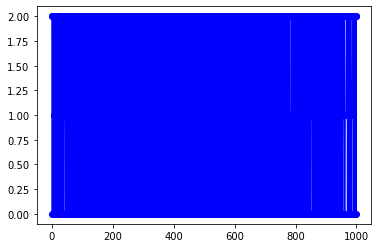

In [62]:
x = np.arange(N)
y = np.matrix([0, 1, 2])
y = np.repeat(y, N, axis = 0)
#print(y)
plt.plot(x, y, 'r-')
plt.plot(x, stato, 'bo-')
plt.show()